# WM-811K: Spatial Features and Gradient Boosting

This notebook explains and inspects the completed alternative to the project's CNN pipeline. It covers feature extraction, optional training, the fitted model, held-out evaluation, and comparison with earlier reported models.

**Default behavior:** inspect the published artifacts without retraining. The displayed Test metrics are recalculated from the included prediction CSV. Optional training requires the separately obtained WM-811K dataset. Historical CNN scores are presentation-reported values, not CNN reruns.

Install dependencies in the selected notebook kernel before running:

```bash
python -m pip install -r spatial_boosting/requirements-notebook.txt
```

Run the cells from top to bottom. The setup supports launching Jupyter from the repository root or this notebook's directory.

In [1]:
from pathlib import Path
import sys, json, subprocess, importlib.metadata

cwd = Path.cwd().resolve()
candidates = [cwd, cwd.parent]
REPO = next((p for p in candidates if (p / "spatial_boosting" / "wafer_features.py").is_file()), None)
if REPO is None:
    raise RuntimeError("Launch this notebook from the repository root or spatial_boosting directory.")
MODEL_DIR = REPO / "spatial_boosting"
RESULTS = MODEL_DIR / "results"
sys.path.insert(0, str(MODEL_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import joblib
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from wafer_features import extract_features, CLASSES
from IPython.display import display

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
print("Python:", sys.version.split()[0])
print({name: importlib.metadata.version(name) for name in ["numpy", "pandas", "scipy", "scikit-learn", "joblib", "matplotlib"]})

Python: 3.12.14
{'numpy': '2.5.4', 'pandas': '3.0.1', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'joblib': '1.6.0', 'matplotlib': '3.11.2'}


## 1. Task and data boundary

The model classifies only eight labeled defect types. It does not determine whether a wafer is normal, classify mixed defects, or diagnose a manufacturing cause.

- Pixel coding: **0 = outside wafer, 1 = good die, 2 = defective die**.
- Original Training/Test: **17,625 / 7,894**.
- Within Training: first lot-grouped validation fold, with 3,525 validation entries.
- Two exact-map copies are removed from candidate fitting, leaving 14,098 fit entries.
- Final selected model is refit on all 17,625 Training entries.

`none` and unlabeled entries are excluded. Lot name and split labels are used for evaluation control, not prediction features.

In [2]:
evaluation = json.loads((RESULTS / "evaluation.json").read_text())
metadata = json.loads((RESULTS / "model_metadata.json").read_text())
bundle = joblib.load(RESULTS / "spatial_model.joblib")
model = bundle["model"]
assert bundle["classes"] == CLASSES
assert model.n_features_in_ == 274
print("Class order:", CLASSES)
display(pd.DataFrame({"Partition": ["Original Training", "Candidate fit", "Validation", "Original Test"],
                      "Wafers": [evaluation["train_count"], evaluation["validation_fit_count"], evaluation["validation_count"], evaluation["test_count"]]}))

Class order: ['Center', 'Donut', 'Edge-Loc', 'Edge-Ring', 'Loc', 'Near-full', 'Random', 'Scratch']


,Partition,Wafers
0,Original Training,17625
1,Candidate fit,14098
2,Validation,3525
3,Original Test,7894


## 2. From pixels to 274 spatial features

A CNN learns convolution filters from pixels. This pipeline first computes fixed spatial summaries, then learns a classifier over those numbers. The summaries encode where defects occur, their density, and aspects of their shape.

Relative coordinates are based on map dimensions, not calibrated physical wafer radius. Regional rates use valid-die counts in the denominator; morphology uses a 64×64 binary mask with the outside region set to zero.

In [3]:
feature_groups = pd.DataFrame([
    ("Overall failure rate", 1, "Defective / valid die"),
    ("Radial density", 16, "Rates in 16 radial bins"),
    ("Angular and radial-angular", 112, "(4+8+16) sectors × 4 regions; sorted"),
    ("Grid density", 80, "Sorted 4×4 and 8×8 rates"),
    ("Coordinates, radius, covariance", 13, "Center displacement, spread, radial quantiles, eigenvalues"),
    ("Connected components / morphology", 28, "4 masks × 7 summaries"),
    ("Smoothed density", 24, "4 Gaussian scales × 6 quantiles")
], columns=["Feature group", "Count", "Meaning"])
assert feature_groups["Count"].sum() == 274
display(feature_groups)

,Feature group,Count,Meaning
0,Overall failure rate,1,Defective / valid die
1,Radial density,16,Rates in 16 radial bins
2,Angular and radial-angular,112,(4+8+16) sectors × 4 regions; sorted
3,Grid density,80,Sorted 4×4 and 8×8 rates
4,"Coordinates, radius, covariance",13,"Center displacement, spread, radial quantiles,..."
5,Connected components / morphology,28,4 masks × 7 summaries
6,Smoothed density,24,4 Gaussian scales × 6 quantiles


### Illustrative patterns — synthetic, not dataset samples

The following maps illustrate the representation, not learned thresholds or measured model performance. Radial density can distinguish central, middle-ring, and outer-ring concentrations. Other feature families are still needed for local and line-like defects.

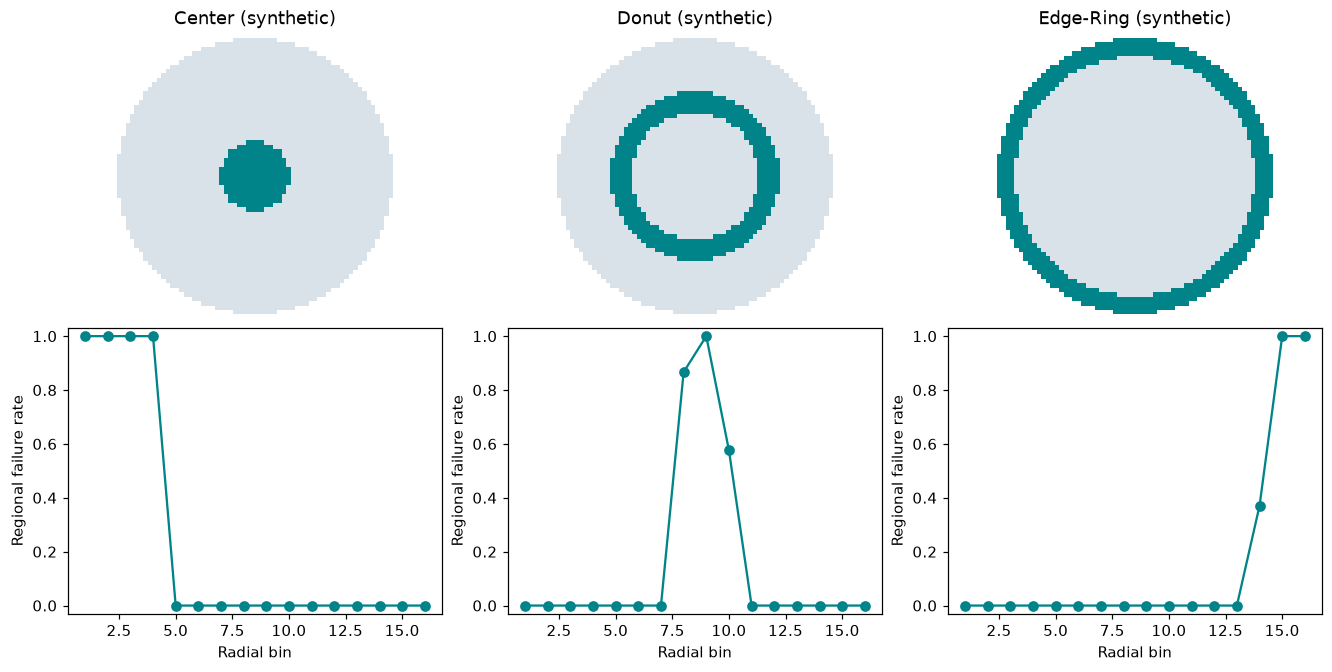

In [4]:
axis = np.linspace(-1, 1, 64)
xx, yy = np.meshgrid(axis, axis)
radius = np.sqrt(xx**2 + yy**2)
valid = radius <= 0.98
conditions = {"Center": radius < 0.25,
              "Donut": (radius > 0.45) & (radius < 0.60),
              "Edge-Ring": radius > 0.85}
illustrations = {}
for name, defect_mask in conditions.items():
    wafer = valid.astype(np.uint8)
    wafer[valid & defect_mask] = 2
    illustrations[name] = wafer

fig, axes = plt.subplots(2, 3, figsize=(12, 6), constrained_layout=True)
for col, (name, wafer) in enumerate(illustrations.items()):
    vector = extract_features(wafer)
    assert vector.shape == (274,) and np.isfinite(vector).all()
    axes[0, col].imshow(wafer, cmap=ListedColormap(["white", "#d9e2e8", "#00848a"]), vmin=0, vmax=2)
    axes[0, col].set_title(name + " (synthetic)")
    axes[0, col].axis("off")
    axes[1, col].plot(np.arange(1, 17), vector[1:17], marker="o", color="#00848a")
    axes[1, col].set(xlabel="Radial bin", ylabel="Regional failure rate", ylim=(-0.03, 1.03))
plt.show()

### Representation limits

Sorting angular/grid values removes position order. This may reduce some directional sensitivity but loses information and does **not** make the complete model rotation invariant. Covariance and other features retain directional effects.

Nearest resampling and morphological opening can remove fine structures. The last radial bin collects outer radii beyond its lower boundary. Feature counts do not imply feature importance, and no feature-removal experiment has been completed.

## 3. How gradient boosting learns

For class $k$, boosting updates an accumulated score:

$$F_{m,k}(x) = F_{m-1,k}(x) + \eta h_{m,k}(x), \qquad \eta = 0.07.$$

A new tree approximates a correction based on the current loss gradients and Hessians. Histogram bins supply candidate split locations. The objective is multiclass log loss. Softmax converts the accumulated scores into class probabilities, and the largest probability determines the prediction.

This is sequential correction, rather than majority voting among independently fitted trees. The model uses one tree per class per iteration: **220 iterations × 8 classes = 1,760 trees**. Probability calibration has not been evaluated.

In [5]:
params = model.get_params()
settings = {key: params[key] for key in ["loss", "learning_rate", "max_iter", "max_leaf_nodes", "min_samples_leaf", "l2_regularization", "max_bins", "early_stopping", "class_weight", "random_state"]}
settings.update({"actual_iterations": model.n_iter_, "trees_per_iteration": model.n_trees_per_iteration_,
                 "total_trees": model.n_iter_ * model.n_trees_per_iteration_})
display(pd.DataFrame({"Setting": list(settings), "Value": [str(v) for v in settings.values()]}))

,Setting,Value
0,loss,log_loss
1,learning_rate,0.07
2,max_iter,220
3,max_leaf_nodes,23
4,min_samples_leaf,20
5,l2_regularization,3
6,max_bins,255
7,early_stopping,False
8,class_weight,None
9,random_state,42


## 4. Validation selection and optional training

Three candidates were compared on one lot-disjoint validation fold. Accuracy is the selection metric, with Macro F1 as tie-breaker. These are **validation**, not Test, scores. The full five-fold experiment was not run.

Only Extra Trees and Random Forest use class balancing. The final histogram boosting model uses `class_weight=None`, no augmentation, and no external pretraining.

In [6]:
validation = pd.DataFrame(json.loads((RESULTS / "validation.json").read_text()))
validation_display = validation.rename(columns={"accuracy": "Validation accuracy (%)", "macro_f1": "Validation Macro F1 (%)"}).copy()
validation_display.iloc[:, 1:] = validation_display.iloc[:, 1:] * 100
display(validation_display.round(2))
assert validation.sort_values(["accuracy", "macro_f1"], ascending=False).iloc[0]["model"] == evaluation["selected_model"]

,model,Validation accuracy (%),Validation Macro F1 (%)
0,extra_trees,96.79,93.88
1,random_forest,95.66,91.32
2,hist_gradient,96.96,93.93


### Optional: rerun training

Leave `RUN_TRAINING=False` to preserve the published artifacts. Enabling it requires the raw pandas pickle and will overwrite model/result files in `results/`. This recomputes the feature cache and trains all three candidates. Nested singleton label arrays and string labels are accepted.

The saved manifest and model metadata describe the published artifact; regenerate them if replacing that artifact with a new run.

In [7]:
RUN_TRAINING = False
DATASET = REPO / "data" / "WM811K.pkl"  # Change this path if needed.
if RUN_TRAINING:
    if not DATASET.is_file():
        raise FileNotFoundError("Obtain WM-811K separately and set DATASET to its pandas pickle.")
    subprocess.run([sys.executable, str(MODEL_DIR / "train_spatial.py"), "--dataset", str(DATASET), "--rebuild-cache"], check=True)
    subprocess.run([sys.executable, str(MODEL_DIR / "verify_model.py")], check=True)
    evaluation = json.loads((RESULTS / "evaluation.json").read_text())
    bundle = joblib.load(RESULTS / "spatial_model.joblib")
    model = bundle["model"]
else:
    print("Training skipped; inspecting the published model and recorded predictions.")

Training skipped; inspecting the published model and recorded predictions.


## 5. Recalculate held-out metrics from the prediction CSV

This cell independently recalculates accuracy, Macro F1, and the confusion matrix from the included per-wafer predictions. It checks consistency of the saved report. It does not regenerate CNN predictions or reload the raw wafer maps.

In [8]:
predictions = pd.read_csv(RESULTS / "test_predictions.csv")
assert len(predictions) == evaluation["test_count"] == 7894
accuracy = accuracy_score(predictions["true"], predictions["predicted"])
macro_f1 = f1_score(predictions["true"], predictions["predicted"], labels=CLASSES, average="macro")
cm = confusion_matrix(predictions["true"], predictions["predicted"], labels=CLASSES)
assert np.isclose(accuracy, evaluation["accuracy"])
assert np.isclose(macro_f1, evaluation["macro_f1"])
assert np.array_equal(cm, evaluation["confusion_matrix"])
print(f"Test accuracy: {accuracy:.4%}")
print(f"Test Macro F1: {macro_f1:.4%}")
report = classification_report(predictions["true"], predictions["predicted"], labels=CLASSES, output_dict=True, zero_division=0)
per_class = pd.DataFrame({name: report[name] for name in CLASSES}).T
per_class[["precision", "recall", "f1-score"]] *= 100
display(per_class.round(2))

Test accuracy: 77.2359%
Test Macro F1: 77.6662%


,precision,recall,f1-score,support
Center,83.97,76.20,79.90,832.0
Donut,62.43,80.82,70.45,146.0
Edge-Loc,81.99,87.70,84.75,2772.0
Edge-Ring,91.15,81.44,86.02,1126.0
Loc,73.21,63.30,67.90,1973.0
Near-full,94.79,95.79,95.29,95.0
Random,85.34,77.04,80.98,257.0
Scratch,48.57,66.23,56.04,693.0


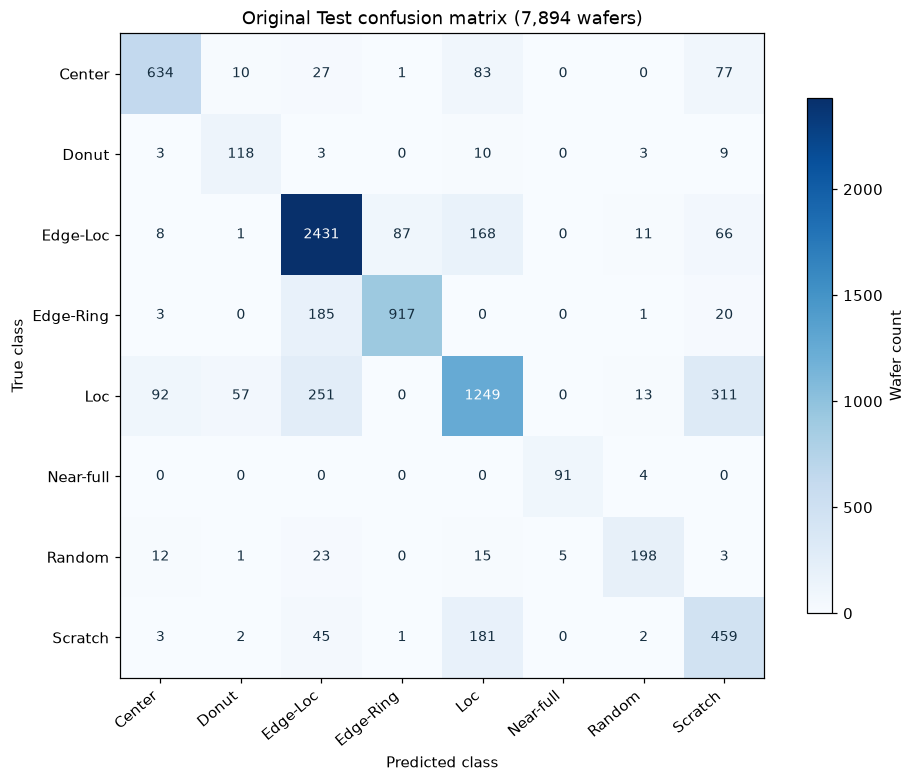

In [9]:
fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)
image = ax.imshow(cm, cmap="Blues")
fig.colorbar(image, ax=ax, label="Wafer count", shrink=0.8)
ax.set(xticks=range(8), yticks=range(8), xticklabels=CLASSES, yticklabels=CLASSES,
       xlabel="Predicted class", ylabel="True class", title="Original Test confusion matrix (7,894 wafers)")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
for i in range(8):
    for j in range(8):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "#152e40", fontsize=9)
plt.show()

## 6. Compare with the earlier reported models

The earlier values below come from the original presentation. Stage 1 Macro F1 is not reported and is left missing. New-model values are calculated above from the CSV. This is a comparison of whole pipelines with different representations and final-fit procedures, not an isolated classifier experiment.

,Model,Test accuracy (%),Test Macro F1 (%)
0,WaferGuard zero-shot,30.63,24.91
1,Transfer Stage 1,59.18,NaN
2,Transfer Stage 2,63.90,64.76
3,CNN baseline,70.09,67.02
4,Spatial boosting,77.24,77.67


Versus CNN: accuracy +7.15 pp; Macro F1 +10.65 pp


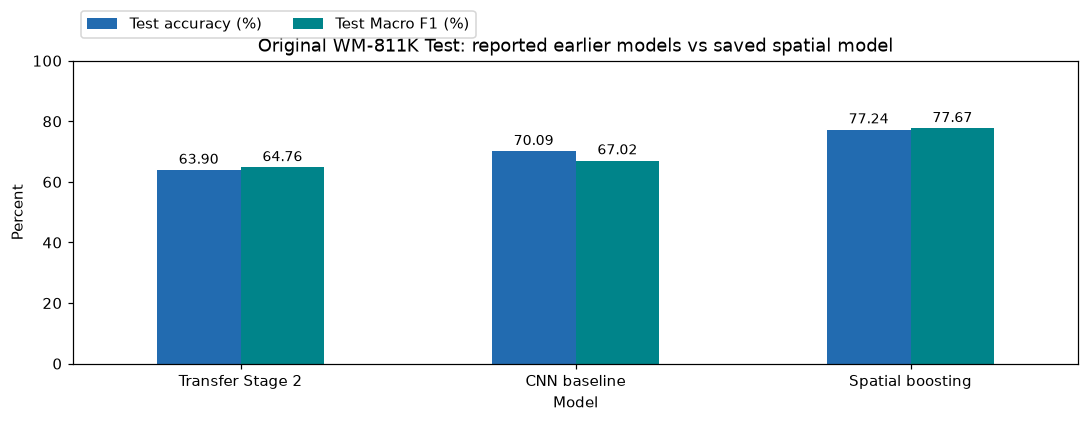

In [10]:
comparison = pd.DataFrame([
    ("WaferGuard zero-shot", 30.63, 24.91),
    ("Transfer Stage 1", 59.18, np.nan),
    ("Transfer Stage 2", 63.90, 64.76),
    ("CNN baseline", 70.09, 67.02),
    ("Spatial boosting", accuracy * 100, macro_f1 * 100)
], columns=["Model", "Test accuracy (%)", "Test Macro F1 (%)"])
display(comparison.round(2))
print(f"Versus CNN: accuracy +{accuracy*100 - 70.09:.2f} pp; Macro F1 +{macro_f1*100 - 67.02:.2f} pp")
plot_data = comparison.iloc[[2, 3, 4]].set_index("Model")
ax = plot_data.plot.bar(figsize=(10, 4), color=["#226bb0", "#00848a"], rot=0, ylim=(0, 100), ylabel="Percent", title="Original WM-811K Test: reported earlier models vs saved spatial model")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2, fontsize=9)
ax.legend(loc="upper left", bbox_to_anchor=(0, 1.19), ncol=2)
plt.tight_layout()
plt.show()

## 7. Generalization and failure analysis

The validation score is not the expected score on unseen lots. The approximate 19.73-point validation-to-Test gap remains large. There are no overlapping Training/Test lot names, but 92 Test maps exactly match a Training map. The duplicate-excluded results below are a **recorded hash audit**, not recomputed from raw maps in this notebook.

In [11]:
clean = evaluation["test_without_training_duplicates"]
display(pd.DataFrame([
    ("Original Test", evaluation["test_count"], evaluation["accuracy"]*100, evaluation["macro_f1"]*100),
    ("Exact Training-map matches excluded", clean["count"], clean["accuracy"]*100, clean["macro_f1"]*100)
], columns=["Subset", "Wafers", "Accuracy (%)", "Macro F1 (%)"]).round(2))
print("Recorded Training/Test lot overlap:", evaluation["train_test_lot_overlap"])
print("Recorded exact-match Test entries:", evaluation["train_test_exact_map_overlap_test_count"])
errors = [(CLASSES[i] + " → " + CLASSES[j], int(cm[i,j])) for i in range(8) for j in range(8) if i != j]
display(pd.DataFrame(sorted(errors, key=lambda x: x[1], reverse=True)[:6], columns=["True → predicted", "Count"]))

,Subset,Wafers,Accuracy (%),Macro F1 (%)
0,Original Test,7894,77.24,77.67
1,Exact Training-map matches excluded,7802,77.01,77.35


Recorded Training/Test lot overlap: 0
Recorded exact-match Test entries: 92


,True → predicted,Count
0,Loc → Scratch,311
1,Loc → Edge-Loc,251
2,Edge-Ring → Edge-Loc,185
3,Scratch → Loc,181
4,Edge-Loc → Loc,168
5,Loc → Center,92


## 8. Why performance may have improved — and what is not proven

- Radial, density, cluster, and covariance summaries expose task-relevant geometry directly, which may reduce the learning burden.
- Relative coordinates and regional rates may reduce some size/die-count effects.
- Sorted density values may reduce some orientation sensitivity, while losing spatial order.
- Regularized boosted trees may suit this feature representation and the available sample size.
- The final model uses **all 17,625 Training wafers**, whereas the historical CNN notebook evaluates a checkpoint trained on its internal fit subset. This difference may contribute to the improvement.

Donut recall is 80.82%, consistent with a useful radial representation, but no ablation demonstrates a specific feature's causal contribution. Scratch recall improves while precision remains 48.57%. Transfer Stage 2 still has higher Near-full recall. No rotation robustness, feature-importance, repeated-seed, or complete five-fold evaluation is claimed.

To separate the effects, use identical fit/validation rows and equivalent final refits, ablate feature groups, hold features fixed while comparing classifiers, and evaluate independent lots.

## 9. Example inference on a synthetic map

This is an API demonstration only. The example is not a labeled Test observation and contributes nothing to the reported accuracy.

In [12]:
example = illustrations["Donut"]
probabilities = model.predict_proba(extract_features(example)[None])[0]
assert np.isfinite(probabilities).all() and np.isclose(probabilities.sum(), 1)
print("Predicted class:", bundle["classes"][int(probabilities.argmax())])
display(pd.Series(probabilities, index=bundle["classes"], name="Uncalibrated probability").sort_values(ascending=False).to_frame())

Predicted class: Donut


,Uncalibrated probability
Donut,0.992297
Scratch,0.004052
Loc,0.003002
Center,0.000282
Random,0.000223
Edge-Loc,0.000070
Edge-Ring,0.000061
Near-full,0.000014


## Further reading

- [Model card and execution instructions](README.md)
- [Detailed comparison and notebook-review notes](../docs/model_comparison.md)
- [Comparison presentation](../reports/model_comparison_learning_principles.pptx)
- [Historical notebook index](../Jupyter_notebook/README.md)
- [scikit-learn HistGradientBoostingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html)

The process-root-cause presentation contains investigation hypotheses and attributed literature figures. Pattern classification alone does not establish a manufacturing cause.